In [2]:
%mamba install pandas numpy matplotlib scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.121 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ certifi             2026.10.23  pyhd8ed1ab_0         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ pandas              3.1.0       np23py313h124dbc7_0  emscripten-forge-4x
+ pysocks             1.7.1       py313h1804a44_3      emscripten-forge-4x
+ requests            2.34.2      pyhcf101f3_0         conda-forge
+ scikit-

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df = pd.read_csv(url)

display(df.head())
print(f"Number of rows: {df.shape[0]}, Number of columns: {df.shape[1]}")

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


Number of rows: 506, Number of columns: 14


In [6]:
df = df.dropna()
df = df.drop_duplicates()
print(f"Data cleaned. Remaining rows: {df.shape[0]}")

Data cleaned. Remaining rows: 506


In [8]:
X = df[['rm']]
y = df['medv']

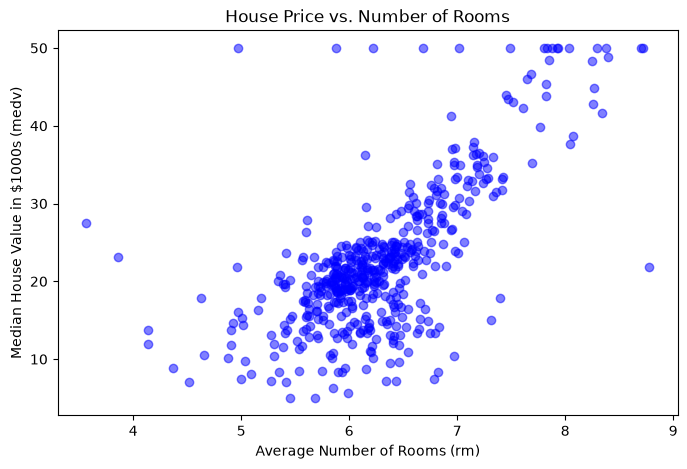

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, alpha=0.5, color='blue')
plt.title("House Price vs. Number of Rooms")
plt.xlabel("Average Number of Rooms (rm)")
plt.ylabel("Median House Value in $1000s (medv)")
plt.show()

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training observations: {X_train.shape[0]}")
print(f"Testing observations: {X_test.shape[0]}")

Training observations: 404
Testing observations: 102


In [12]:
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intercept (c): {model.intercept_:.4f}")
print(f"Coefficient (m): {model.coef_[0]:.4f}")

Intercept (c): -36.2463
Coefficient (m): 9.3483


In [13]:
y_pred = model.predict(X_test)

results_df = pd.DataFrame({'Actual Price': y_test, 'Predicted Price': y_pred})
display(results_df.head(10))

,Actual Price,Predicted Price
173,23.6,23.732383
274,32.4,26.929502
491,13.6,19.684568
72,22.8,20.451129
452,16.1,22.619935
76,20.0,22.451666
316,17.8,19.039536
140,14.0,21.470094
471,19.6,21.984251
500,16.8,20.095894


In [15]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Absolute Error (MAE): 4.48
Mean Squared Error (MSE): 46.14
Root Mean Squared Error (RMSE): 6.79
R-squared (R2): 0.3708


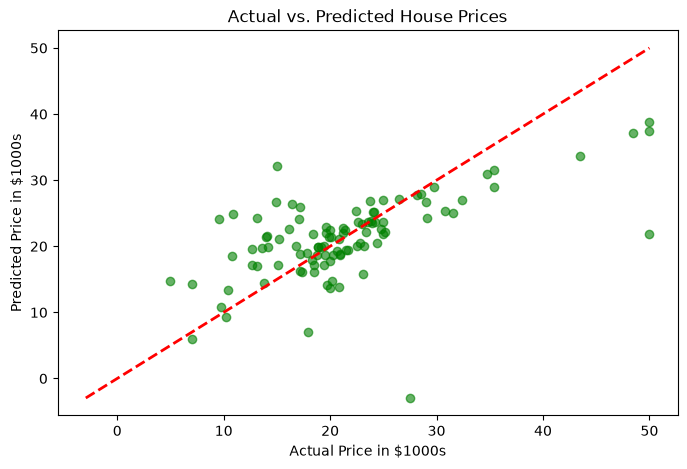

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color='green')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)

plt.title("Actual vs. Predicted House Prices")
plt.xlabel("Actual Price in $1000s")
plt.ylabel("Predicted Price in $1000s")
plt.show()

In [17]:
new_house_rooms = np.array([[6.5]]) 
new_prediction = model.predict(new_house_rooms)

print(f"Predicted price for a house with 6.5 rooms: ${new_prediction[0] * 1000:,.2f}")

/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Predicted price for a house with 6.5 rooms: $24,517.64
